# MSゲート：振幅較正によるPauli近似精度のチャネル距離評価

**目的**：MSゲートの誤差チャネルから同定したコヒーレント $XX$ 成分を駆動振幅で較正すると、
元チャネルとPauli-twirled近似との距離がどれだけ減るかを定量化する。
さらに、較正後に残る非Pauli成分から近似の限界を調べる。

主指標は **diamond距離 $\epsilon_{\rm P}=\frac12\|\mathcal E-\mathcal T(\mathcal E)\|_\diamond$**。
Choiトレース距離とPTM Frobenius距離を補助指標として併記する。
diamond距離はSDPの主問題・双対問題を解き、数値的な下界・上界・ギャップまで保存する。

このノートは**既存の較正前後のQPT結果を後処理する**。新しいmaster equationの時間発展、
振幅の再最適化、QEC回路計算は行わない。距離の改善は保存チャネルについての結果であり、
Hamiltonian近似・フォノンcutoff・ODE誤差の保証とは区別する。

作成日：2026-09-30。実装：`pauli_channel_distance.py`。

## 読む順序と実行方法

1. 0–2節：実行条件、入力データ、表現規約とCPTP確認。
2. 3–5節：距離の定義、diamond距離の上下界とSDP。
3. 6–8節：全温度での計算、較正前後比較、残留非Pauli成分。
4. 9–11節：解析例、計算結果の解釈、再現性と限界。

上から順に **Run All** する。カーネル一覧の **Python (MS Pauli distance)** は、
CVXPYとSCSを導入済みの `.venv/channel-distance/bin/python` を使用する。
別のカーネルでも、先頭セルは実行中の `sys.executable` を表示し、CVXPYまたはSCSが
未導入なら **そのPython** の `-m pip` で `requirements-pauli-distance.txt` を導入する。
初回の導入にはネットワーク接続が必要。自動導入を止めたい場合は
`AUTO_INSTALL_SDP_DEPENDENCIES=False` とし、導入済みの専用カーネルを選ぶ。
基本依存は NumPy / SciPy / pandas / Matplotlib / QuTiP / ipykernel、SDPは CVXPY + SCS。
ノート外のターミナルで `pip` を実行すると、別のPythonに入る場合があるため注意する。

出力先：`results/pauli_twirl_channel_distance/`。既存の入力チャネルは変更しない。

## 0. 設定と実行環境

`NBAR_VALUES=[0.01, 1.0, 2.0, 3.0, 4.0]` の5点を評価する。`RUN_SDP=True` が正式評価の既定値。
`False` にすると解析的な上下界だけを計算し、SDP値を推測で補完しない。
`SOLVER_TOL` はスケーリング後の最適化問題への許容誤差、`GAP_ATOL/RTOL` は最終的な距離の
上下界の幅を受理する基準であり、物理的な許容誤差ではない。

In [2]:
from pathlib import Path
import os, sys, json, hashlib, platform, inspect, subprocess, importlib.util
from datetime import datetime, timezone
import importlib.metadata as metadata

PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                     if (p / 'pauli_channel_distance.py').is_file()), None)
if PROJECT_ROOT is None:
    raise RuntimeError('プロジェクトルート、またはその配下から実行してください。')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
OUTPUT_DIR = PROJECT_ROOT / 'results/pauli_twirl_channel_distance'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
os.environ.setdefault('MPLCONFIGDIR', str(OUTPUT_DIR / '.matplotlib'))

NBAR_VALUES = [0.01, 1.0, 2.0, 3.0, 4.0]
RUN_SDP = True
AUTO_INSTALL_SDP_DEPENDENCIES = True
SDP_SOLVER = 'SCS'
SOLVER_TOL = 1e-8
GAP_ATOL, GAP_RTOL = 1e-8, 1e-5
CP_TOL, TP_TOL = 1e-9, 1e-8
FOCUS_NBAR = 4.0
print('実行中のPython:', sys.executable, flush=True)
if RUN_SDP:
    missing = [name for name in ('cvxpy', 'scs') if importlib.util.find_spec(name) is None]
    if missing:
        if not AUTO_INSTALL_SDP_DEPENDENCIES:
            raise ImportError(f'{missing} が {sys.executable} にありません。'
                              'Python (MS Pauli distance) を選ぶか、'
                              'AUTO_INSTALL_SDP_DEPENDENCIES=True で先頭セルを再実行してください。')
        requirements = PROJECT_ROOT / 'requirements-pauli-distance.txt'
        print(f'{missing} を実行中のPythonに導入します: {requirements}', flush=True)
        try:
            subprocess.run([sys.executable, '-m', 'pip', 'install', '-r', str(requirements)],
                           check=True)
        except subprocess.CalledProcessError as exc:
            raise RuntimeError('依存の導入に失敗しました。上のpip出力を確認するか、'
                               '導入済みの Python (MS Pauli distance) に切り替えてください。') from exc
        importlib.invalidate_caches()
    try:
        import cvxpy as cp
    except ImportError as exc:
        raise ImportError(f'CVXPYを {sys.executable} で読み込めません。'
                          'カーネルを再起動して先頭セルから実行するか、'
                          'Python (MS Pauli distance) に切り替えてください。') from exc
    if SDP_SOLVER not in cp.installed_solvers():
        raise RuntimeError(f'{SDP_SOLVER} が利用できません。利用可能: {cp.installed_solvers()}')
    print('CVXPY:', cp.__version__, '; path:', cp.__file__, flush=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import qutip as qp
from scipy.linalg import expm
from IPython.display import display, Markdown, Code
import pauli_channel_distance as pcd

pd.set_option('display.max_columns', 24)
pd.set_option('display.width', 180)
plt.rcParams.update({'figure.dpi': 120, 'savefig.dpi': 220, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
print('Python:', sys.executable)
print('Output:', OUTPUT_DIR)
print('SDP:', RUN_SDP, '; solvers:', cp.installed_solvers() if RUN_SDP else 'not requested')

実行中のPython: /Library/Developer/CommandLineTools/usr/bin/python3
['cvxpy', 'scs'] を実行中のPythonに導入します: /Users/hirainoa/Desktop/量子/project/Moon_shot__高橋PJ/MS_gate_Hirai/requirements-pauli-distance.txt
Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 16.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 935.1/935.1 kB 19.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [cvxpy]━━━━━ 3/4 [cvxpy]
CVXPY: 1.6.5 ; path: /Users/hirainoa/Library/Python/3.9/lib/python/site-packages/cvxpy/__init__.py
Python: /Library/Developer/CommandLineTools/usr/bin/python3
Output: /Users/hirainoa/Desktop/量子/project/Moon_shot__高橋PJ/MS_gate_Hirai/results/pauli_twirl_channel_distance
SDP: True ; solvers: ['CLARABEL', 'OSQP', 'SCIPY', 'SCS']


## 1. 何と何を比較するか

実際のゲートを $\mathcal G$、理想MSゲートを $\mathcal U_\star$ とすると、保存データの規約は

$$\mathcal E=\mathcal G\circ\mathcal U_\star^{-1},\qquad
\mathcal G=\mathcal E\circ\mathcal U_\star.$$

つまり誤差は理想ゲートの**後**に置く。コード名 `undo_before_actual` と
「post-gate noise」はこの合成順序で一致する。
比較は、それぞれの較正条件の $\mathcal E_{\rm before/after}$ と
$\mathcal T(\mathcal E_{\rm before/after})$ の間で行う。
較正前のPauliモデルを較正後のチャネルに使い回す比較ではない。

較正後データは駆動振幅を変えて再QPTしたものであり、$\log\mathcal E$ から $h_{XX}$ を
数式上引いただけのチャネルではない。各 $\bar n$ で独立に較正している。

入力は `results/pauli_twirl_channel_distance/inputs/` の以下の3ファイルで、CPTP射影後の行列を主解析に使う。

この5点用の入力は `prepare_pauli_distance_inputs.py` で準備した。\(\bar n=0.01,1,2,4\) は既存の保存行列を再利用し、\(\bar n=3\) は保存済み較正前行列から同じ振幅フィードバックを行い、較正後だけ新たにmaster equationのQPTを実行した。補間は使わない。較正条件と入力のハッシュは `preparation_manifest.json` に保存してある。このノート自体の再実行では、準備済み行列を読み込むだけなので物理シミュレーションを繰り返さない。

| ファイル | 用途 |
|---|---|
| `projected_chi_before_after.npz` | 主解析の較正前後χ行列 |
| `post_gate_noise_chi_before_after.npz` | 元行列・Pauli順序・合成規約、射影感度の確認 |
| `channel_comparison_long.csv` | 振幅倍率・$h_{XX}$・既存の完全分解係数との対応 |

`gamma_XX_per_gate` の三成分フィット値と `taxonomy_S_XX` の完全基底分解値は異なるので混同しない。
このノートの残留成分の表示には `taxonomy_*` 列を用いる。

In [3]:
SOURCE_DIR = PROJECT_ROOT / 'results/pauli_twirl_channel_distance/inputs'
PROJECTED_PATH = SOURCE_DIR / 'projected_chi_before_after.npz'
RAW_PATH = SOURCE_DIR / 'post_gate_noise_chi_before_after.npz'
SUMMARY_PATH = SOURCE_DIR / 'channel_comparison_long.csv'
with np.load(PROJECTED_PATH, allow_pickle=False) as archive:
    saved = {k: archive[k].copy() for k in archive.files}
with np.load(RAW_PATH, allow_pickle=False) as archive:
    raw = {k: archive[k].copy() for k in archive.files}
labels, paulis = pcd.pauli_basis(2)
d = 4
assert labels == list(raw['pauli_labels'])
assert np.array_equal(saved['n_bar'], raw['n_bar'])
assert str(raw['convention']) == 'N_post = S_noisy @ inverse(S_ideal)'
nbars = saved['n_bar'] if NBAR_VALUES is None else np.asarray(NBAR_VALUES, dtype=float)
indices = []
for nbar in nbars:
    matches = np.flatnonzero(np.isclose(saved['n_bar'], nbar, rtol=0, atol=1e-10))
    if len(matches) != 1:
        raise ValueError(f'一意な保存データがありません: nbar={nbar}')
    indices.append(int(matches[0]))
if len(set(indices)) != len(indices):
    raise ValueError('NBAR_VALUES に重複があります')
source_summary = pd.read_csv(SUMMARY_PATH)
print('Convention:', str(raw['convention']))
print('Pauli order:', ', '.join(labels))
print('Selected nbar:', nbars)

Convention: N_post = S_noisy @ inverse(S_ideal)
Pauli order: II, IX, IY, IZ, XI, XX, XY, XZ, YI, YX, YY, YZ, ZI, ZX, ZY, ZZ
Selected nbar: [0.01 1.   2.   3.   4.  ]


## 2. χ・Choi・PTMの規約と入力の健全性

標準Pauli演算子を $P_a$ とし、$\operatorname{Tr}(P_a^\dagger P_b)=d\delta_{ab}$ とする。
本ノートの標準χは

$$\mathcal E(\rho)=\sum_{a,b}\chi_{ab}P_a\rho P_b^\dagger,\qquad
\operatorname{Tr}\chi=1\quad(\mathrm{TP}).$$

列優先ベクトル化を使い、$V=[\mathrm{vec}(P_0),\ldots,\mathrm{vec}(P_{15})]$ とする。
非正規化Choi行列と正規化Choi状態は

$$J(\mathcal E)=V\chi V^\dagger
=\sum_{i,j}|i\rangle\langle j|_{\rm in}\otimes\mathcal E(|i\rangle\langle j|)_{\rm out},
\qquad \omega_{\mathcal E}=J(\mathcal E)/d.$$

$V^\dagger V=dI$ なので、$\omega_{\mathcal E}$ と $\chi$ はユニタリ同値である。
CPは $J\succeq0$、TPは $\operatorname{Tr}_{\rm out}J=I_{\rm in}$ で検査する。
**trace-oneだけではTPを保証しない**ため、部分トレースも実際に確認する。

### 保存済みQuTiP χの符号変換

このリポジトリの保存χは `qp.to_chi` に由来する。使用環境のQuTiP 5.0.4では
変換基底が $\mathrm{vec}(P_a^*)$ で、奇数個の $Y$ を含むPauliに符号が付く。
保存済みtrace-one行列を $\chi^{\rm saved}$ とすると

$$\chi=D\chi^{\rm saved}D,\qquad D_{aa}=(-1)^{\#Y(P_a)}.$$

QuTiPの未正規化χのtraceは $d^2=16$。保存ファイルは既にtrace-oneなので、さらに16で割らない。
下のセルで各行列の `qp.to_choi` と独立実装の $V\chi V^\dagger$ を照合し、規約が変われば停止する。
この符号変換は今回のχノルムとPauli確率を変えないが、物理的なチャネルの作用とTP判定には必要である。

新しいCPTP射影は行わない。許容誤差内の微小な負固有値を記録し、基準を超える入力は停止する。

In [4]:
channels, raw_channels, diagnostic_rows = {}, {}, []
super_dims = [[[2, 2], [2, 2]], [[2, 2], [2, 2]]]
for index in indices:
    nbar = float(saved['n_bar'][index])
    for condition in ('before', 'after'):
        stored_chi = saved[f'chi_{condition}'][index]
        chi = pcd.qutip_chi_to_canonical(stored_chi, labels)
        raw_chi = pcd.qutip_chi_to_canonical(raw[f'chi_{condition}'][index], labels)
        qobj = qp.Qobj(stored_chi * d**2, dims=super_dims, superrep='chi')
        choi_reference = qp.to_choi(qobj).full()
        convention_error = np.linalg.norm(pcd.chi_to_choi(chi, paulis) - choi_reference)
        assert convention_error < 1e-11, 'QuTiP χの規約を再確認してください'
        checks = pcd.channel_diagnostics(chi, paulis, CP_TOL, TP_TOL)
        raw_checks = pcd.channel_diagnostics(raw_chi, paulis, CP_TOL, TP_TOL)
        assert checks['cptp_within_tolerance'], (nbar, condition, checks)
        projection_bounds = pcd.diamond_bounds(pcd.chi_to_choi(chi - raw_chi, paulis), d)
        diagnostic_rows.append({
            'n_bar': nbar, 'condition': condition, **checks,
            'qutip_choi_conversion_difference': float(convention_error),
            'raw_min_choi_eigenvalue': raw_checks['choi_min_eigenvalue'],
            'raw_tp_frobenius_error': raw_checks['choi_tp_frobenius_error'],
            'raw_to_projected_chi_frobenius': float(np.linalg.norm(chi - raw_chi)),
            'raw_to_projected_diamond_upper': projection_bounds['diamond_upper_abs_choi'],
            'twirl_distance_projection_sensitivity_upper': 2*projection_bounds['diamond_upper_abs_choi'],
        })
        channels[(nbar, condition)] = chi
        raw_channels[(nbar, condition)] = raw_chi
diagnostics = pd.DataFrame(diagnostic_rows)
display(diagnostics)

,n_bar,condition,chi_trace_error,choi_hermiticity_error,choi_min_eigenvalue,choi_tp_frobenius_error,cptp_within_tolerance,qutip_choi_conversion_difference,raw_min_choi_eigenvalue,raw_tp_frobenius_error,raw_to_projected_chi_frobenius,raw_to_projected_diamond_upper,twirl_distance_projection_sensitivity_upper
0,0.01,before,3.587324e-42,5.208351e-16,1.471214e-07,2.220792e-16,True,0.0,1.471214e-07,1.778149e-15,7.152437e-16,9.907475e-16,1.981495e-15
1,0.01,after,0.000000e+00,4.440920e-16,1.362670e-07,3.845927e-16,True,0.0,1.362670e-07,3.339332e-15,1.443197e-15,2.155034e-15,4.310068e-15
2,1.00,before,5.739719e-42,4.163412e-16,1.429901e-07,2.482719e-16,True,0.0,1.429901e-07,2.322362e-15,7.055734e-16,1.257306e-15,2.514612e-15
3,1.00,after,2.220446e-16,3.140321e-16,1.617770e-07,3.845934e-16,True,0.0,1.617770e-07,3.913941e-15,1.167370e-15,2.012491e-15,4.024982e-15
4,2.00,before,0.000000e+00,5.229647e-16,1.541273e-07,3.849215e-16,True,0.0,1.541273e-07,3.741727e-15,5.740576e-16,1.489769e-15,2.979537e-15
5,2.00,after,1.291437e-41,2.719615e-16,9.087302e-08,3.140187e-16,True,0.0,9.087302e-08,3.972367e-15,6.310451e-16,1.382137e-15,2.764275e-15
6,3.00,before,0.000000e+00,2.793533e-16,-2.478549e-12,1.607789e-16,True,0.0,-2.125066e-07,3.978087e-15,5.585450e-08,1.034410e-07,2.068820e-07
7,3.00,after,9.183550e-41,4.441229e-16,-7.702970e-13,2.482841e-16,True,0.0,-8.158087e-08,2.941646e-15,2.144144e-08,3.925969e-08,7.851938e-08
8,4.00,before,0.000000e+00,5.537617e-16,1.551293e-07,5.462515e-16,True,0.0,1.551293e-07,4.040277e-15,8.079168e-16,1.806402e-15,3.612803e-15
9,4.00,after,0.000000e+00,7.692053e-16,-1.559936e-12,1.570173e-16,True,0.0,-1.719712e-09,5.680510e-15,4.519516e-10,8.334039e-10,1.666808e-09


## 3. Pauli twirlと補助距離

2量子ビットのPauli集合 $\mathcal P_2$ は全16個で、

$$\mathcal T(\mathcal E)(\rho)=\frac1{16}\sum_{P\in\mathcal P_2}
P^\dagger\mathcal E(P\rho P^\dagger)P.$$

異なるPauli成分の交差項が平均で消えるため、標準χでは
$\chi_{\rm PT}=\operatorname{diag}(\chi)$。
Pauli確率は $p_a=\chi_{aa}$ であり、完全なCPTPチャネルなら $p_a\ge0,\sum_a p_a=1$。
小さな数値負値は診断で扱い、確率を黙ってclipしない。

PTMは $R_{ab}=\operatorname{Tr}[P_a^\dagger\mathcal E(P_b)]/d$。
Pauli twirlはPTMでも対角化に一致する。

| 指標 | 定義 | 解釈 |
|---|---|---|
| 絶対Frobenius距離 $D_F$ | $\|R-R_{\rm PT}\|_F=d\|\chi-\chi_{\rm PT}\|_F$ | 行列全体で落とした成分の大きさ。確率ではない |
| 相対Frobenius距離 $\eta_F$ | $D_F/\|R-I\|_F$ | 元の残留誤差に対する近似差。恒等成分で希釈しない |
| Choiトレース距離 $D_J$ | $\frac12\|\omega_{\mathcal E}-\omega_{\rm PT}\|_1$ | 最大エンタングル入力を用いた出力差。diamond距離の下界 |

ここで $\|A\|_1$ は**特異値の和**であり、要素の絶対値の和でもFrobeniusノルムでもない。
$D_J=\frac12\|\chi-\chi_{\rm PT}\|_1$ は上のユニタリ同値性から従う。
恒等チャネルでは相対距離は $0/0$ なので `NaN` とする。

平均infidelityは $r=\frac{d}{d+1}(1-\chi_{II,II})$ で、twirlが対角要素を保存するため
**元チャネルとそのtwirlで厳密に同じ**。従って $r$ の一致は近似精度の証拠にならない。
また、$\mathcal T(e^K)$ と $e^{\mathcal T(K)}$ は一般に異なる。
生成元を対角化して指数を取る処理でチャネルのtwirlを代用しない。

In [5]:
# 16 Pauliの群平均と、chi/PTMの対角化の一致を独立に確認する。
rng = np.random.default_rng(20260930)
random_matrix = rng.normal(size=(d, d)) + 1j*rng.normal(size=(d, d))
rho_check = random_matrix @ random_matrix.conj().T
rho_check /= np.trace(rho_check)
twirl_checks = []
for (nbar, condition), chi in channels.items():
    group_output = sum(p @ pcd.apply_chi(chi, p @ rho_check @ p, paulis) @ p
                       for p in paulis) / len(paulis)
    diagonal_output = pcd.apply_chi(pcd.pauli_twirl_chi(chi), rho_check, paulis)
    m = pcd.distance_metrics(chi, paulis)
    difference = np.linalg.norm(group_output - diagonal_output)
    assert difference < 1e-12
    assert m['ptm_chi_frobenius_identity_error'] < 1e-11
    assert m['ptm_twirl_diagonalization_error'] < 1e-11
    assert m['twirl_infidelity_difference'] == 0
    twirl_checks.append({'n_bar': nbar, 'condition': condition,
                         'explicit_group_twirl_error': float(difference),
                         'min_pauli_probability': float(np.diag(chi).real.min()),
                         'pauli_probability_sum': float(np.trace(chi).real)})
twirl_checks = pd.DataFrame(twirl_checks)
display(twirl_checks)

,n_bar,condition,explicit_group_twirl_error,min_pauli_probability,pauli_probability_sum
0,0.01,before,7.017134e-17,4.195862e-08,1.0
1,0.01,after,4.770551e-17,4.019077e-08,1.0
2,1.00,before,1.008605e-16,5.039826e-08,1.0
3,1.00,after,1.399896e-16,4.644680e-08,1.0
4,2.00,before,1.396914e-16,5.407197e-08,1.0
5,2.00,after,1.545756e-16,4.987984e-08,1.0
6,3.00,before,8.313084e-17,6.193629e-08,1.0
7,3.00,after,8.994254e-17,4.139731e-08,1.0
8,4.00,before,7.920272e-17,4.404970e-08,1.0
9,4.00,after,9.501491e-17,5.119679e-08,1.0


## 4. 主指標：diamond距離と解析的上下界

$\Delta=\mathcal E-\mathcal T(\mathcal E)$ とすると、

$$\epsilon_{\rm P}=\frac12\|\Delta\|_\diamond
=\max_{\rho_{SA}}\frac12\|(\Delta\otimes\mathcal I_A)(\rho_{SA})\|_1.$$

入力と同じ次元 $d=4$ の補助系で十分である。CPTPチャネルの差なら、任意の入力・補助系・測定に対して、
**ある測定事象の確率のずれは $\epsilon_{\rm P}$ 以下**となる。等事前確率で両チャネルを一回識別する
最適成功確率は $(1+\epsilon_{\rm P})/2$。これは平均ゲートの誤り確率そのものではない。

非正規化Choi差を $J_\Delta=V(\chi-\chi_{\rm PT})V^\dagger$ とすると、

$$L_J=\frac{\|J_\Delta\|_1}{2d}
\ \le\ \epsilon_{\rm P}
\ \le\ U_{|J|}=\frac12\|\operatorname{Tr}_{\rm out}|J_\Delta|\|_\infty
\ \le\ U_{\rm simple}=\frac12\|J_\Delta\|_1=dL_J.$$

Hermitianな $J$ に対して $|J|=\sum_k|\lambda_k||v_k\rangle\langle v_k|$。
下界は最大エンタングル入力の評価、中央の上界は次節の双対問題に $Z=|J|$ を代入した値である。
正の部分トレース行列では最大固有値がoperator normとなる。
以前の簡単な上下界 $L_J\le\epsilon_{\rm P}\le dL_J$ も比較用に保持する。

上下界が近ければ、SDP前でも精度のよい区間が得られる。遠い場合に中点を「diamond距離」と呼ばない。

## 5. SDPによるdiamond距離の実装と数値精度

Hermiticity-preservingな $\Delta$ に対して、$J=J_\Delta$ の入力⊗出力順序で次を解く。
両最適値は **$\|\Delta\|_\diamond$（距離の2倍）**なので、最終出力を2で割る。

**主問題**：$\rho$ は入力側の密度行列、$W$ はHermitian変数。

$$\begin{aligned}
\text{maximize}\quad &\operatorname{Tr}(JW)\\
\text{subject to}\quad &\rho\succeq0,\quad\operatorname{Tr}\rho=1,\\
&-\rho\otimes I_{\rm out}\preceq W\preceq\rho\otimes I_{\rm out}.
\end{aligned}$$

**双対問題**：$Z$ はHermitian変数、$t$ は実数。

$$\begin{aligned}
\text{minimize}\quad &t\\
\text{subject to}\quad &Z\succeq J,\quad Z\succeq-J,\\
&\operatorname{Tr}_{\rm out}Z\preceq tI_{\rm in}.
\end{aligned}$$

有限精度ソルバーの返す目的関数値だけを採用せず、以下を行う。

1. $J$ をoperator normで割り、約1のスケールで両問題を解いてから元に戻す。
2. ソルバーが返した**入力状態** $\rho$ の小さな負固有値を除きtrace-oneにする。
   $K=\sqrt\rho\otimes I$ から $\frac12\|KJK\|_1$ を計算し、有効な入力による下界を得る。
3. 双対変数を $Z'=Z+sI$ とし、$Z'\succeq\pm J$ を満たす小さなshiftと丸め誤差用余裕を加える。
   $\frac12\lambda_{\max}(\operatorname{Tr}_{\rm out}Z')$ を上界とする。
4. 解析的な上下界と組み合わせ、最終区間 $[L,U]$ を狭める。
   $U-L\le\texttt{GAP\_ATOL}+\texttt{GAP\_RTOL}\,U$ のときだけ中点を推定値として表示する。

ここで補正するのは最適化変数であり、**物理チャネルを変更していない**。
`optimal_inaccurate` でも区間を調べ、受理条件を満たさなければ推定値は `NaN`、正式計算は停止する。
微小ギャップはSDPの数値精度を示すが、区間演算による数学的な丸め誤差保証ではなく、
入力のODE誤差・Hamiltonian打切り誤差も含まない。

実装は [Watrous (2012)](https://arxiv.org/abs/1207.5726) のChoi表現によるSDPを、
Hermiticity-preserving写像に特殊化した主双対形式である。
以下に実際に呼び出すソースを表示する。

In [6]:
display(Code(inspect.getsource(pcd.diamond_distance_sdp), language='python'))

def diamond_distance_sdp(choi_delta, d, solver="SCS", solver_tolerance=1e-8,
                         gap_atol=1e-8, gap_rtol=1e-5):
    """Solve HP diamond primal and dual, returning a checked numerical bracket.

    Primal: max Tr(J W), rho>=0, Tr(rho)=1, -rho(x)I <= W <= rho(x)I.
    Dual: min t, Z>=+J, Z>=-J, Tr_out Z <= t I.
    Both objectives give the full norm; output distances are divided by 2.

    For reliability, project ONLY the optimizing rho onto density matrices
    and recompute a feasible-input lower bound. Shift ONLY the dual witness
    Z to satisfy Z>=+/-J and recompute an upper bound. The channel is never
    projected. Bounds are mathematical in exact arithmetic, numerical here:
    this is not an interval-arithmetic certificate or an ODE error bound.
    """
    import cvxpy as cp

    bounds = diamond_bounds(choi_delta, d)
    j_raw = hermitian(choi_delta)
    scale = float(np.linalg.norm(j_raw, 2))
    if scale == 0:
        return {
            "diamond_sdp_lower": 0.0, "diamond_sdp_upper": 0.0,
            "diamond_distance_estimate": 0.0, "diamond_sdp_gap": 0.0,
            "diamond_sdp_relative_gap": 0.0, "sdp_accepted": True,
            "sdp_primal_status": "zero_map", "sdp_dual_status": "zero_map",
            "sdp_solver": solver,
        }
    if solver not in cp.installed_solvers():
        raise RuntimeError(f"{solver} is unavailable; installed: {cp.installed_solvers()}")
    j = j_raw / scale
    rho = cp.Variable((d, d), hermitian=True)
    witness = cp.Variable((d*d, d*d), hermitian=True)
    sandwich = cp.kron(rho, np.eye(d))
    primal = cp.Problem(cp.Maximize(cp.real(cp.trace(j @ witness))), [
        rho >> 0, cp.trace(rho) == 1,
        sandwich - witness >> 0, sandwich + witness >> 0,
    ])
    z = cp.Variable((d*d, d*d), hermitian=True)
    t = cp.Variable()
    trace_z = cp.bmat([
        [cp.trace(z[i*d:(i+1)*d, k*d:(k+1)*d]) for k in range(d)]
        for i in range(d)
    ])
    dual = cp.Problem(cp.Minimize(t), [
        z - j >> 0, z + j >> 0, t*np.eye(d) - trace_z >> 0,
    ])
    options = {"solver": solver, "verbose": False}
    if solver == "SCS":
        options.update(eps=solver_tolerance, max_iters=100000)
    elif solver == "CLARABEL":
        options.update(tol_gap_abs=solver_tolerance, tol_gap_rel=solver_tolerance,
                       tol_feas=solver_tolerance, max_iter=300)
    primal.solve(**options)
    dual.solve(**options)
    valid_statuses = {cp.OPTIMAL, cp.OPTIMAL_INACCURATE}
    if (primal.status not in valid_statuses or dual.status not in valid_statuses
            or rho.value is None or z.value is None or witness.value is None):
        raise RuntimeError(f"SDP failed: primal={primal.status}, dual={dual.status}")

    rho_raw = hermitian(rho.value)
    eig, vectors = np.linalg.eigh(rho_raw)
    clipped = np.maximum(eig, 0)
    if clipped.sum() <= 0:
        raise RuntimeError("SDP returned an invalid input density matrix")
    sqrt_rho = (vectors * np.sqrt(clipped / clipped.sum())) @ vectors.conj().T
    k = np.kron(sqrt_rho, np.eye(d))
    lower_input = scale * trace_norm(k @ j @ k) / 2

    z_raw = hermitian(z.value)
    min_dual = min(np.linalg.eigvalsh(z_raw - j).min(), np.linalg.eigvalsh(z_raw + j).min())
    safety = 1e-10 * max(1.0, np.linalg.norm(z_raw, 2))
    shift = max(0.0, -float(min_dual)) + safety
    z_feasible = z_raw + shift*np.eye(d*d)
    upper_dual = scale * float(np.linalg.eigvalsh(hermitian(partial_trace_output(z_feasible, d))).max()) / 2
    lower = max(lower_input, bounds["diamond_lower_choi"])
    upper = min(upper_dual, bounds["diamond_upper_abs_choi"])
    gap = upper - lower
    accepted = bool(-1e-12 <= gap <= gap_atol + gap_rtol * max(upper, 1e-15))
    # If numerical crossing is beyond roundoff, do not publish an estimate.
    sandwich_raw = np.kron(rho_raw, np.eye(d))
    primal_min = min(
        eig.min(),
        np.linalg.eigvalsh(hermitian(sandwich_raw - witness.value)).min(),
        np.linalg.eigvalsh(hermitia

## 6. 較正前後・全温度での正式評価

各行に対して、(i) χからPauli twirlを作る、(ii)補助距離と解析界を計算、
(iii)同じ差写像のSDPを解く、(iv)既存の $h_{XX}$ と較正倍率を対応させる。
CSVの既存infidelityと入力χが一致することも確認し、異なるrunの結果が混ざった場合に停止する。

ここで距離を最小化する振幅の再探索はしない。あくまで**既存の $h_{XX}$ 較正が、
独立の距離指標も改善するか**を評価する。

In [7]:
records = []
for (nbar, condition), chi in channels.items():
    row = {'n_bar': nbar, 'condition': condition, **pcd.distance_metrics(chi, paulis)}
    if RUN_SDP:
        j_delta = pcd.chi_to_choi(chi - pcd.pauli_twirl_chi(chi), paulis)
        row.update(pcd.diamond_distance_sdp(j_delta, d, solver=SDP_SOLVER,
                   solver_tolerance=SOLVER_TOL, gap_atol=GAP_ATOL, gap_rtol=GAP_RTOL))
    else:
        row.update({'diamond_distance_estimate': np.nan, 'sdp_accepted': False,
                    'sdp_primal_status': 'not_run', 'sdp_dual_status': 'not_run'})
    matched = source_summary.loc[np.isclose(source_summary.n_bar, nbar, rtol=0, atol=1e-10)
                                 & source_summary.condition.eq(condition)]
    if len(matched) != 1:
        raise ValueError(f'CSV対応が一意ではありません: {(nbar, condition)}')
    source = matched.iloc[0]
    assert abs(row['average_infidelity'] - source.average_infidelity) < 1e-9
    for field in ['A_factor', 'h_XX_rad_per_gate', 'taxonomy_S_XX',
                  'taxonomy_S_IX', 'taxonomy_S_XI', 'taxonomy_C_IX_XI']:
        row[field] = float(source[field])
    records.append(row)
    if RUN_SDP:
        print(f"nbar={nbar:g}, {condition:6s}: epsilon_P={row['diamond_distance_estimate']:.9g}, "
              f"gap={row['diamond_sdp_gap']:.2e}, accepted={row['sdp_accepted']}")
metrics = pd.DataFrame(records)
metrics.to_csv(OUTPUT_DIR / 'channel_distances_long.csv', index=False)
if RUN_SDP and not metrics.sdp_accepted.all():
    raise RuntimeError('未収束のSDPがあります。診断CSVと許容誤差を確認してください。')
display(metrics[['n_bar', 'condition', 'diamond_distance_estimate', 'diamond_lower_choi',
                 'diamond_upper_abs_choi', 'diamond_upper_simple', 'ptm_frobenius_distance',
                 'relative_error_frobenius_distance', 'average_infidelity']])

nbar=0.01, before: epsilon_P=0.0144353168, gap=5.53e-10, accepted=True
nbar=0.01, after : epsilon_P=0.00127130445, gap=1.99e-12, accepted=True
nbar=1, before: epsilon_P=0.0299328843, gap=7.16e-09, accepted=True
nbar=1, after : epsilon_P=0.0023947622, gap=6.69e-12, accepted=True
nbar=2, before: epsilon_P=0.0451510108, gap=1.05e-08, accepted=True
nbar=2, after : epsilon_P=0.00352205798, gap=1.88e-10, accepted=True
nbar=3, before: epsilon_P=0.0598883479, gap=1.92e-09, accepted=True
nbar=3, after : epsilon_P=0.00463731733, gap=3.58e-11, accepted=True
nbar=4, before: epsilon_P=0.0741110252, gap=6.58e-09, accepted=True
nbar=4, after : epsilon_P=0.0057443297, gap=8.53e-12, accepted=True


,n_bar,condition,diamond_distance_estimate,diamond_lower_choi,diamond_upper_abs_choi,diamond_upper_simple,ptm_frobenius_distance,relative_error_frobenius_distance,average_infidelity
0,0.01,before,0.014435,0.014435,0.014435,0.057741,0.077624,0.991106,0.001947
1,0.01,after,0.001271,0.001271,0.001271,0.005085,0.004356,0.407167,0.001819
2,1.00,before,0.029933,0.029933,0.029933,0.119732,0.162369,0.992431,0.003644
3,1.00,after,0.002395,0.002395,0.002395,0.009579,0.008832,0.460467,0.003104
4,2.00,before,0.045151,0.045151,0.045151,0.180604,0.245676,0.990554,0.005981
5,2.00,after,0.003522,0.003522,0.003522,0.014088,0.013337,0.447305,0.004796
6,3.00,before,0.059888,0.059888,0.059889,0.239553,0.326431,0.987592,0.008878
7,3.00,after,0.004637,0.004637,0.004638,0.018549,0.017796,0.416980,0.006882
8,4.00,before,0.074111,0.074111,0.074111,0.296444,0.404423,0.983893,0.012281
9,4.00,after,0.005744,0.005744,0.005745,0.022977,0.022223,0.383272,0.009366


### 較正前後の比較と判定

改善倍率は距離の **before / after**。厳密な改善判定に対応するものとして、
数値上下界が $U_{\rm after}<L_{\rm before}$ を満たすかを記録する。
この判定は指定された2チャネルについてのもので、任意のパラメータへの普遍的主張ではない。
区間から改善倍率自体も $[L_b/U_a,\,U_b/L_a]$ と評価できる。

In [8]:
before = metrics.query("condition == 'before'").drop(columns='condition')
after = metrics.query("condition == 'after'").drop(columns='condition')
paired = before.merge(after, on='n_bar', suffixes=('_before', '_after'), validate='one_to_one')
paired['frobenius_reduction_factor'] = paired.ptm_frobenius_distance_before / paired.ptm_frobenius_distance_after
paired['diamond_reduction_factor'] = paired.diamond_distance_estimate_before / paired.diamond_distance_estimate_after
if RUN_SDP:
    lower_name, upper_name = 'diamond_sdp_lower', 'diamond_sdp_upper'
else:
    lower_name, upper_name = 'diamond_lower_choi', 'diamond_upper_abs_choi'
paired['improvement_lower_ratio'] = paired[f'{lower_name}_before'] / paired[f'{upper_name}_after']
paired['improvement_upper_ratio'] = paired[f'{upper_name}_before'] / paired[f'{lower_name}_after']
paired['improvement_from_separated_bounds'] = paired[f'{upper_name}_after'] < paired[f'{lower_name}_before']
paired.to_csv(OUTPUT_DIR / 'channel_distances_paired.csv', index=False)
display(paired[['n_bar', 'h_XX_rad_per_gate_before', 'h_XX_rad_per_gate_after',
               'diamond_distance_estimate_before', 'diamond_distance_estimate_after',
               'diamond_reduction_factor', 'frobenius_reduction_factor',
               'relative_error_frobenius_distance_after', 'improvement_from_separated_bounds']])

,n_bar,h_XX_rad_per_gate_before,h_XX_rad_per_gate_after,diamond_distance_estimate_before,diamond_distance_estimate_after,diamond_reduction_factor,frobenius_reduction_factor,relative_error_frobenius_distance_after,improvement_from_separated_bounds
0,0.01,0.013736,0.000102,0.014435,0.001271,11.354728,17.821542,0.407167,True
1,1.00,0.028806,0.000212,0.029933,0.002395,12.499314,18.383722,0.460467,True
2,2.00,0.043740,0.000312,0.045151,0.003522,12.819497,18.420822,0.447305,True
3,3.00,0.058377,0.000390,0.059888,0.004637,12.914438,18.342995,0.416980,True
4,4.00,0.072711,0.000434,0.074111,0.005744,12.901597,18.198657,0.383272,True


## 7. 図：絶対距離・相対距離・改善倍率

左上が主結果。SDP計算時のエラーバーは **SDP上下界の幅のみ**で、
物理モデルの誤差棒や統計信頼区間ではない。小さすぎる場合はマーカーに隠れる。
相対Frobenius距離は残留誤差に対する比であり、縦軸の38%等を誤り確率と解釈しない。
両条件の絶対距離が温度と共に増えても、較正による改善と矛盾しない。

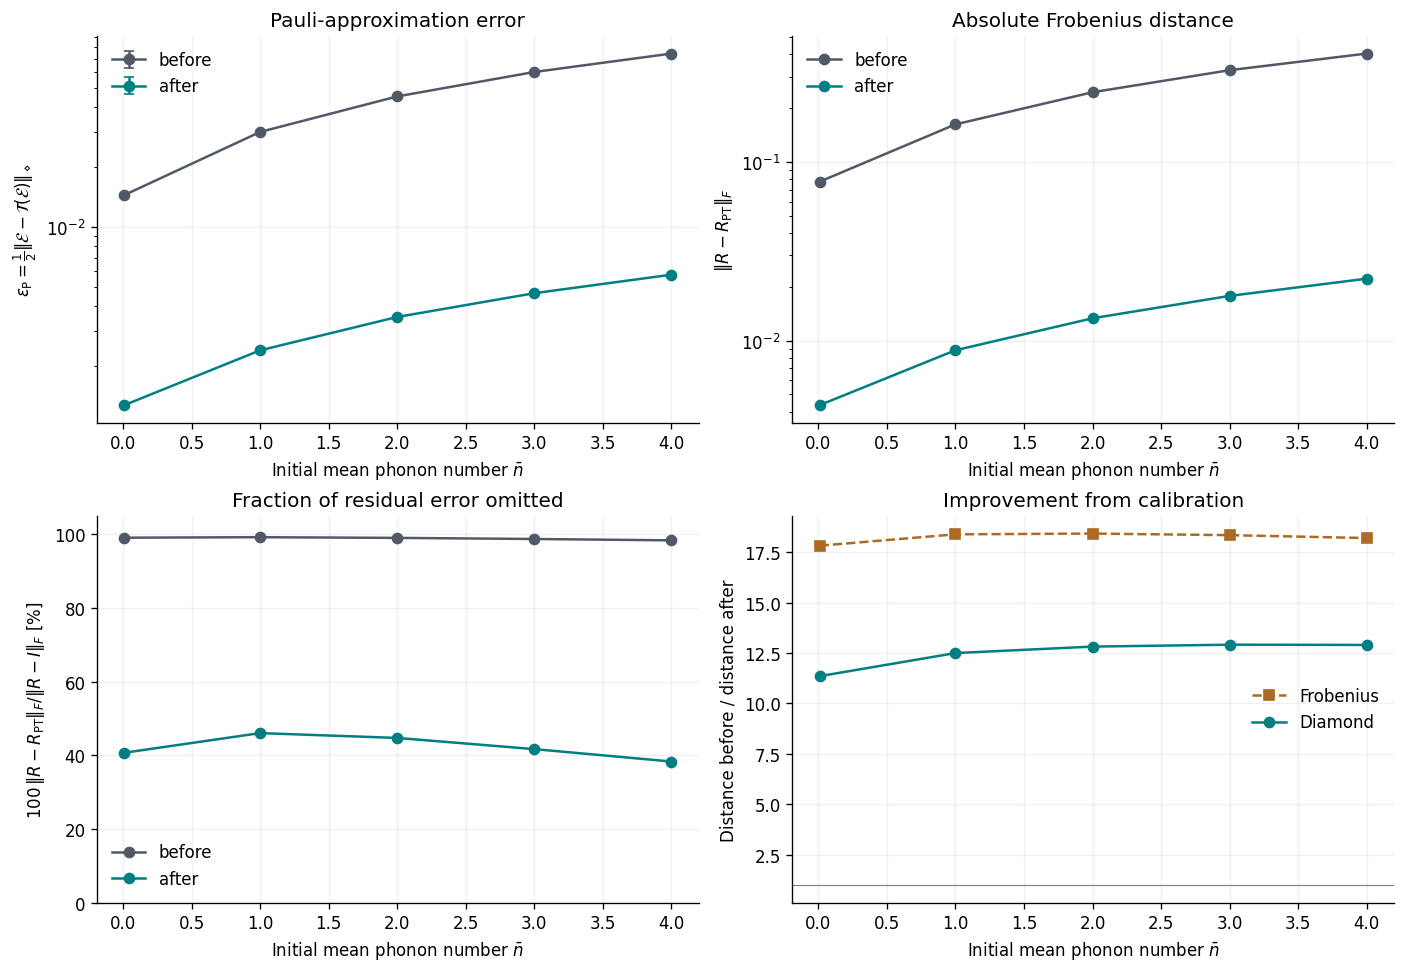

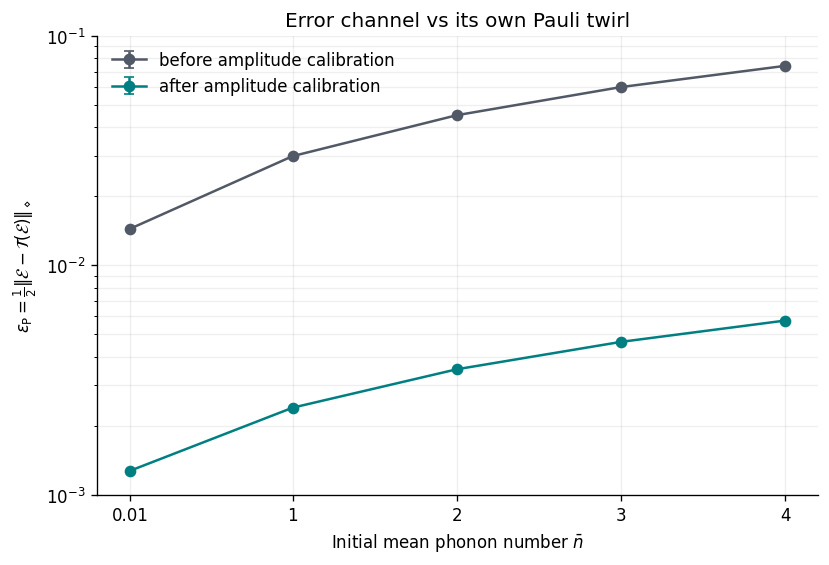

In [9]:
colors = {'before': '#515866', 'after': '#007f82'}
fig, axes = plt.subplots(2, 2, figsize=(11.6, 8.0), constrained_layout=True)
for condition in ('before', 'after'):
    block = metrics.loc[metrics.condition.eq(condition)].sort_values('n_bar')
    x = block.n_bar.to_numpy()
    if RUN_SDP:
        y = block.diamond_distance_estimate.to_numpy()
        yerr = np.maximum(0, np.vstack([y-block.diamond_sdp_lower, block.diamond_sdp_upper-y]))
        axes[0, 0].errorbar(x, y, yerr=yerr, fmt='o-', capsize=3,
                           label=condition, color=colors[condition])
    else:
        axes[0, 0].fill_between(x, block.diamond_lower_choi.to_numpy(),
                               block.diamond_upper_abs_choi.to_numpy(), alpha=.2,
                               color=colors[condition], label=f'{condition}: analytic bounds')
    axes[0, 1].plot(x, block.ptm_frobenius_distance, 'o-', color=colors[condition], label=condition)
    axes[1, 0].plot(x, 100*block.relative_error_frobenius_distance, 'o-', color=colors[condition], label=condition)
axes[0, 0].set(title='Pauli-approximation error', ylabel=r'$\epsilon_{\rm P}=\frac{1}{2}\|\mathcal{E}-\mathcal{T}(\mathcal{E})\|_\diamond$', yscale='log')
axes[0, 1].set(title='Absolute Frobenius distance', ylabel=r'$\|R-R_{\rm PT}\|_F$', yscale='log')
axes[1, 0].set(title='Fraction of residual error omitted', ylabel=r'$100\,\|R-R_{\rm PT}\|_F/\|R-I\|_F$ [%]', ylim=(0, 105))
axes[1, 1].plot(paired.n_bar, paired.frobenius_reduction_factor, 's--', label='Frobenius', color='#ac6b24')
if RUN_SDP:
    axes[1, 1].plot(paired.n_bar, paired.diamond_reduction_factor, 'o-', label='Diamond', color=colors['after'])
axes[1, 1].axhline(1, color='gray', lw=.7)
axes[1, 1].set(title='Improvement from calibration', ylabel='Distance before / distance after')
for ax in axes.flat:
    ax.set_xlabel(r'Initial mean phonon number $\bar n$')
    ax.grid(alpha=.18)
    ax.legend(frameon=False)
for ext in ('png', 'pdf'):
    fig.savefig(OUTPUT_DIR / f'channel_distance_before_after.{ext}')
plt.show()

# Diamond距離だけの図も、論文の主図として使えるように別途保存する。
fig_diamond, ax_diamond = plt.subplots(figsize=(6.8, 4.6), constrained_layout=True)
for condition in ('before', 'after'):
    block = metrics.loc[metrics.condition.eq(condition)].sort_values('n_bar')
    x = block.n_bar.to_numpy()
    if RUN_SDP:
        y = block.diamond_distance_estimate.to_numpy()
        yerr = np.maximum(0, np.vstack([y-block.diamond_sdp_lower, block.diamond_sdp_upper-y]))
        ax_diamond.errorbar(x, y, yerr=yerr, fmt='o-', capsize=3,
                           color=colors[condition], label=f'{condition} amplitude calibration')
    else:
        ax_diamond.fill_between(x, block.diamond_lower_choi.to_numpy(),
                                 block.diamond_upper_abs_choi.to_numpy(), alpha=.25,
                                 color=colors[condition], label=f'{condition}: analytic bounds')
ax_diamond.set(xlabel=r'Initial mean phonon number $\bar n$',
               ylabel=r'$\epsilon_{\rm P}=\frac{1}{2}\|\mathcal{E}-\mathcal{T}(\mathcal{E})\|_\diamond$',
               title='Error channel vs its own Pauli twirl', yscale='log')
ax_diamond.set_xticks(nbars, [f'{n:g}' for n in nbars])
ax_diamond.set_ylim(10**np.floor(np.log10(metrics.diamond_lower_choi.min())),
                     10**np.ceil(np.log10(metrics.diamond_upper_abs_choi.max())))
ax_diamond.grid(alpha=.2, which='both')
ax_diamond.legend(frameon=False)
for ext in ('png', 'pdf'):
    fig_diamond.savefig(OUTPUT_DIR / f'diamond_distance_vs_nbar.{ext}')
plt.show()

### CPTP射影への感度

元行列と保存済み射影後行列の差を $\delta=\mathcal E_{\rm projected}-\mathcal E_{\rm raw}$ とすると、
twirlはdiamond normに関して縮小的なので

$$|\epsilon_{\rm P}(\mathcal E_{\rm projected})-\epsilon_{\rm P}(\mathcal E_{\rm raw})|
\le\tfrac12\|\delta-\mathcal T(\delta)\|_\diamond
\le\|\delta\|_\diamond.$$

従って $2U(\delta)$ を射影による距離変化の上界として用いる。これは射影操作の影響だけであり、
元のODE誤差を推定したものではない。元行列が厳密なCPTPでなくても、この線形写像のノルム不等式は使える。

In [10]:
projection_audit = diagnostics.merge(metrics[['n_bar', 'condition', 'diamond_lower_choi']],
                                     on=['n_bar', 'condition'], validate='one_to_one')
projection_audit['projection_sensitivity_over_distance_lower'] = (
    projection_audit.twirl_distance_projection_sensitivity_upper / projection_audit.diamond_lower_choi)
display(projection_audit[['n_bar', 'condition', 'raw_to_projected_chi_frobenius',
                         'twirl_distance_projection_sensitivity_upper',
                         'projection_sensitivity_over_distance_lower']])
if RUN_SDP:
    display(metrics[['n_bar', 'condition', 'sdp_primal_status', 'sdp_dual_status',
                     'diamond_sdp_lower', 'diamond_sdp_upper', 'diamond_sdp_gap',
                     'diamond_sdp_relative_gap', 'sdp_accepted']])

,n_bar,condition,raw_to_projected_chi_frobenius,twirl_distance_projection_sensitivity_upper,projection_sensitivity_over_distance_lower
0,0.01,before,7.152437e-16,1.981495e-15,1.372672e-13
1,0.01,after,1.443197e-15,4.310068e-15,3.390272e-12
2,1.00,before,7.055734e-16,2.514612e-15,8.400836e-14
3,1.00,after,1.167370e-15,4.024982e-15,1.680744e-12
4,2.00,before,5.740576e-16,2.979537e-15,6.599049e-14
5,2.00,after,6.310451e-16,2.764275e-15,7.848464e-13
6,3.00,before,5.585450e-08,2.068820e-07,3.454462e-06
7,3.00,after,2.144144e-08,7.851938e-08,1.693207e-05
8,4.00,before,8.079168e-16,3.612803e-15,4.874853e-14
9,4.00,after,4.519516e-10,1.666808e-09,2.901658e-07


,n_bar,condition,sdp_primal_status,sdp_dual_status,diamond_sdp_lower,diamond_sdp_upper,diamond_sdp_gap,diamond_sdp_relative_gap,sdp_accepted
0,0.01,before,optimal,optimal,0.014435,0.014435,5.528129e-10,3.829586e-08,True
1,0.01,after,optimal,optimal,0.001271,0.001271,1.992184e-12,1.567039e-09,True
2,1.00,before,optimal,optimal,0.029933,0.029933,7.160176e-09,2.392077e-07,True
3,1.00,after,optimal,optimal,0.002395,0.002395,6.691551e-12,2.794244e-09,True
4,2.00,before,optimal,optimal,0.045151,0.045151,1.047135e-08,2.319183e-07,True
5,2.00,after,optimal,optimal,0.003522,0.003522,1.878076e-10,5.332324e-08,True
6,3.00,before,optimal,optimal,0.059888,0.059888,1.918714e-09,3.203819e-08,True
7,3.00,after,optimal,optimal,0.004637,0.004637,3.583987e-11,7.728578e-09,True
8,4.00,before,optimal,optimal,0.074111,0.074111,6.578626e-09,8.876716e-08,True
9,4.00,after,optimal,optimal,0.005744,0.005744,8.531397e-12,1.485186e-09,True


## 8. 較正後に何が残るか

$h_{XX}\simeq0$ は $\chi$ の全非対角成分が消えることを意味しない。
例えば $L=IX+XI$ のcollective dissipatorは

$$\mathcal D[L]=\mathcal D[IX]+\mathcal D[XI]+
\bigl(IX\rho XI+XI\rho IX-\{XX,\rho\}\bigr).$$

交差項は $\chi_{IX,XI}$ だけでなく $\chi_{II,XX}$ の実部にも現れ得る。
**$|\chi_{II,XX}|$ 全体をコヒーレント誤差と同一視しない。**
一方、対角成分 $p_{XX}$ は二量子ビットの相関誤差であってもPauliモデルに含まれる。
「相関誤差」と「非Pauli誤差」は別の区分である。

以下では全非対角要素を順位付けし、代表温度の較正前後を表示する。
各共役対の寄与率 $2|\chi_{ab}|^2/\|\chi_{\rm off}\|_F^2$ は二乗Frobenius量について加法的である。
**この寄与率をdiamond距離の成分別寄与と解釈してはいけない。**

In [11]:
component_records = []
for (nbar, condition), chi in channels.items():
    off = chi - pcd.pauli_twirl_chi(chi)
    total_square = float(np.linalg.norm(off)**2)
    for a in range(len(labels)):
        for b in range(a+1, len(labels)):
            value = chi[a, b]
            component_records.append({'n_bar': nbar, 'condition': condition,
                'Pauli_a': labels[a], 'Pauli_b': labels[b], 'real': value.real,
                'imag': value.imag, 'absolute_value': abs(value),
                'fraction_of_offdiag_frobenius_squared': 2*abs(value)**2/total_square if total_square else np.nan})
components = pd.DataFrame(component_records).sort_values(
    ['n_bar', 'condition', 'absolute_value'], ascending=[True, True, False])
focus = float(nbars[np.argmin(abs(nbars-FOCUS_NBAR))])
for condition in ('before', 'after'):
    print(f'nbar={focus:g}, {condition}')
    display(components.loc[np.isclose(components.n_bar, focus) & components.condition.eq(condition)].head(8))
display(metrics.loc[np.isclose(metrics.n_bar, focus),
    ['condition', 'h_XX_rad_per_gate', 'taxonomy_S_XX', 'taxonomy_S_IX',
     'taxonomy_S_XI', 'taxonomy_C_IX_XI']])

nbar=4, before


,n_bar,condition,Pauli_a,Pauli_b,real,imag,absolute_value,fraction_of_offdiag_frobenius_squared
964,4.0,before,II,XX,-2.424699e-03,7.141025e-02,7.145140e-02,9.988470e-01
977,4.0,before,IX,XI,2.424699e-03,-3.046803e-08,2.424699e-03,1.150252e-03
1061,4.0,before,YX,ZI,6.008712e-05,1.262183e-09,6.008712e-05,7.063830e-07
1004,4.0,before,IZ,XY,6.006372e-05,2.286287e-09,6.006372e-05,7.058329e-07
993,4.0,before,IY,XZ,-5.738900e-05,2.286287e-09,5.738900e-05,6.443693e-07
1056,4.0,before,YI,ZX,-5.735910e-05,-1.262183e-09,5.735910e-05,6.436979e-07
982,4.0,before,IX,YX,1.936765e-08,-7.103444e-10,1.938067e-08,7.348777e-14
996,4.0,before,IY,YY,-1.587925e-08,8.925144e-09,1.821562e-08,6.491806e-14


nbar=4, after


,n_bar,condition,Pauli_a,Pauli_b,real,imag,absolute_value,fraction_of_offdiag_frobenius_squared
1084,4.0,after,II,XX,-2.760562e-03,4.269676e-04,2.793386e-03,5.056128e-01
1097,4.0,after,IX,XI,2.760562e-03,2.137477e-08,2.760562e-03,4.938002e-01
1176,4.0,after,YI,ZX,-4.848774e-05,4.031424e-10,4.848774e-05,1.523421e-04
1113,4.0,after,IY,XZ,-4.847223e-05,-2.607014e-09,4.847223e-05,1.522447e-04
1181,4.0,after,YX,ZI,4.668201e-05,-4.064027e-10,4.668201e-05,1.412067e-04
1124,4.0,after,IZ,XY,4.667284e-05,-2.603754e-09,4.667284e-05,1.411512e-04
1080,4.0,after,II,IX,1.272772e-09,-5.469209e-08,5.470690e-08,1.939279e-10
1172,4.0,after,YI,YX,6.657122e-09,-5.239203e-08,5.281328e-08,1.807351e-10


,condition,h_XX_rad_per_gate,taxonomy_S_XX,taxonomy_S_IX,taxonomy_S_XI,taxonomy_C_IX_XI
8,before,0.072711,0.004293,0.002476,0.002476,0.002451
9,after,0.000434,0.005191,0.002820,0.002820,0.002795


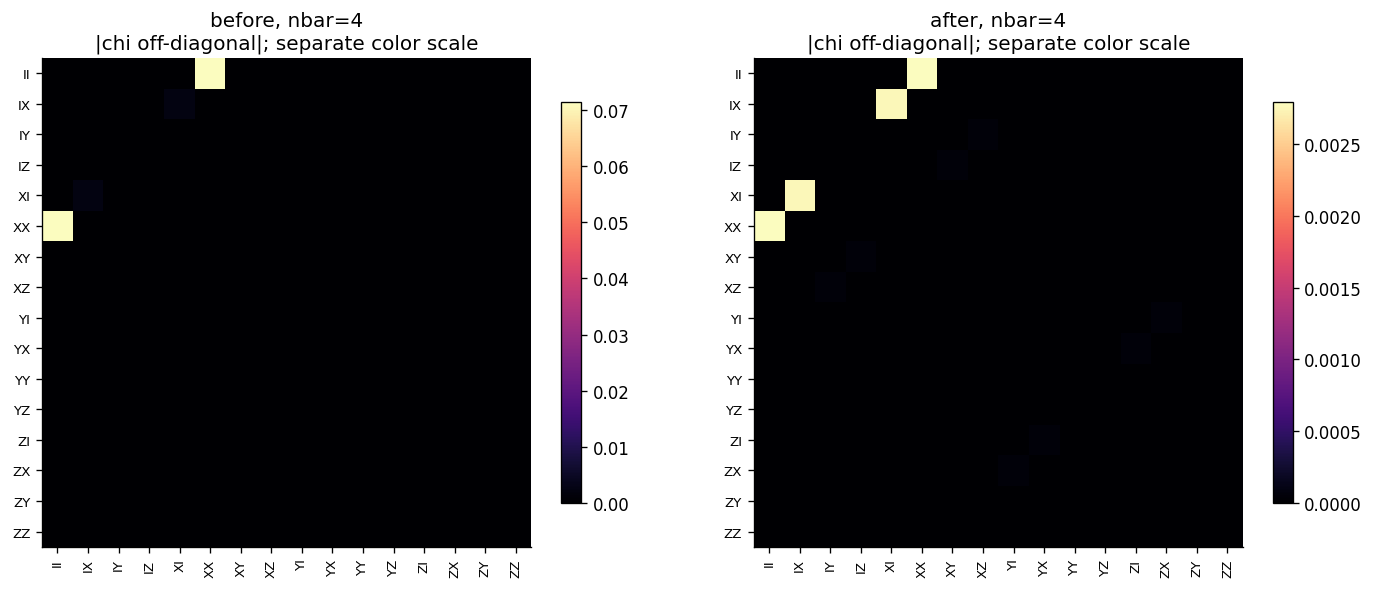

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), constrained_layout=True)
for ax, condition in zip(axes, ('before', 'after')):
    chi = channels[(focus, condition)]
    off = np.abs(chi - pcd.pauli_twirl_chi(chi))
    # Separate scales deliberately expose each residual structure; compare norms in the main figure.
    plot = ax.imshow(off, cmap='magma', interpolation='nearest')
    ax.set(xticks=range(16), yticks=range(16), xticklabels=labels, yticklabels=labels,
           title=f'{condition}, nbar={focus:g}\n|chi off-diagonal|; separate color scale')
    ax.tick_params(axis='x', labelrotation=90, labelsize=8)
    ax.tick_params(axis='y', labelsize=8)
    fig.colorbar(plot, ax=ax, shrink=.82)
for ext in ('png', 'pdf'):
    fig.savefig(OUTPUT_DIR / f'residual_offdiagonal_nbar_{focus:g}.{ext}')
plt.show()

## 9. 解析例：コヒーレント誤差を抑える意味

純粋な $XX$ 回転誤差 $U_h=e^{-ihXX}=\cos h\,I-i\sin h\,XX$ を考える。
ここでは正の $h$ にこの符号を用いる。距離は符号に依存しない。

$$\mathcal U_h(\rho)=\cos^2h\,\rho+\sin^2h\,XX\rho XX-i\sin h\cos h[XX,\rho].$$

twirlは最後の項を消す。$XX$ の固有値は $\pm1$ なので $\|[XX,\cdot]\|_\diamond=2$。
上界は三角不等式、達成は両固有空間の等重ね合わせ入力で確認できる。従って

$$\epsilon_{\rm P}(\mathcal U_h)=|\sin h\cos h|=\frac{|\sin2h|}{2}=O(|h|),$$
$$p_{XX}=\sin^2h=O(h^2),\qquad r=\frac45\sin^2h.$$

小さい $h$ では平均infidelityよりもPauli近似のチャネル差の方が一次で大きくなる。
これは純粋回転モデルの解析解であり、実際の混合ノイズにこの式をそのまま当てはめない。
実データでは $h_{XX}$ をゼロにしても前節の非Pauli散逸が残る。

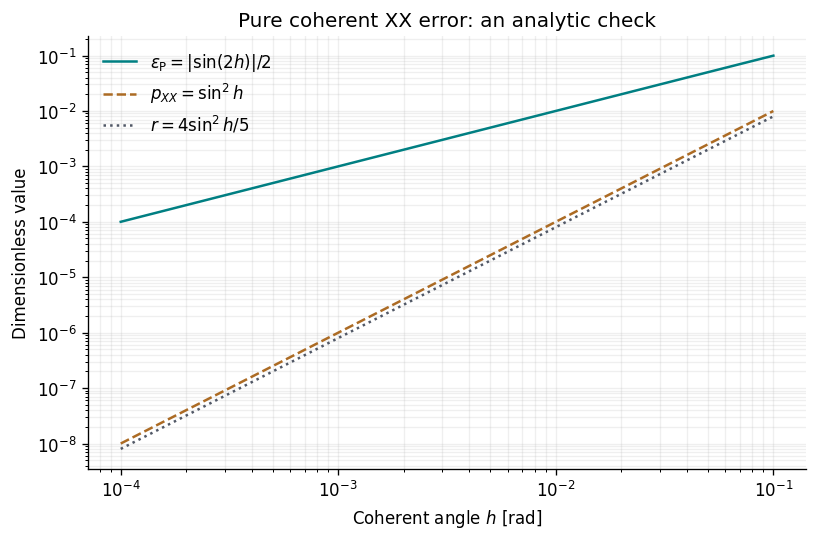

In [13]:
toy_rows = []
xx = labels.index('XX')
for h in np.logspace(-4, -1, 25):
    coefficients = np.zeros(16, complex)
    coefficients[0], coefficients[xx] = np.cos(h), -1j*np.sin(h)
    chi = np.outer(coefficients, coefficients.conj())
    m = pcd.distance_metrics(chi, paulis)
    exact = abs(np.sin(2*h))/2
    assert np.isclose(m['diamond_lower_choi'], exact, atol=1e-12)
    assert np.isclose(m['diamond_upper_abs_choi'], exact, atol=1e-12)
    assert np.isclose(m['average_infidelity'], 4/5*np.sin(h)**2, atol=1e-12)
    toy_rows.append({'h': h, 'exact_diamond_distance': exact, 'pauli_xx_probability': np.sin(h)**2,
                    'average_infidelity': m['average_infidelity']})
toy = pd.DataFrame(toy_rows)
fig, ax = plt.subplots(figsize=(6.7, 4.4), constrained_layout=True)
ax.loglog(toy.h, toy.exact_diamond_distance, label=r'$\epsilon_{\rm P}=|\sin(2h)|/2$', color='#007f82')
ax.loglog(toy.h, toy.pauli_xx_probability, '--', label=r'$p_{XX}=\sin^2h$', color='#ac6b24')
ax.loglog(toy.h, toy.average_infidelity, ':', label=r'$r=4\sin^2h/5$', color='#515866')
ax.set(xlabel=r'Coherent angle $h$ [rad]', ylabel='Dimensionless value', title='Pure coherent XX error: an analytic check')
ax.grid(alpha=.2, which='both')
ax.legend(frameon=False)
for ext in ('png', 'pdf'):
    fig.savefig(OUTPUT_DIR / f'coherent_xx_scaling.{ext}')
plt.show()

## 10. この結果から言えること・言えないこと

**評価する主張**：保存された物理条件と較正手順において、$h_{XX}$ を抑えると元チャネルと
Pauli近似の距離が低下する。残留距離も数値で示す。

**「十分に正確」の基準は用途で決まる**。例えば許容する測定事象の絶対確率誤差を
$\tau$ と定めれば、$\epsilon_{\rm P}\le\tau$ は単一ゲートの十分条件になる。
何も指定せず $\epsilon_{\rm P}$ が小さそうだから十分と判定しない。
また、$\epsilon_{\rm P}$ は最悪ケースの上限であり、すべての入力で同じ差が生じるわけではない。

ゲートごとに独立したCPTPチャネルとして合成できる場合、回路中の $m$ 個の置換に対して

$$\frac12\|\mathcal C-\mathcal C_{\rm PT}\|_\diamond
\le\sum_{k=1}^{m}\epsilon_{{\rm P},k}$$

がtelescopingとCPTP写像の縮小性から従う。ただし一般に緩い上界で、論理誤り率の予測精度とは同じではない。
運動モードがリセットされず履歴を保持する場合、単一ゲートの縮約チャネルの単純合成を仮定できない。

**今回の範囲外**：通常のinfidelity最小化との同条件比較、較正点からのドリフト、
cutoff/時間刻み/ODE許容誤差の収束、高次LD・多モードモデル、QEC性能。
現在のHamiltonianは第一側帯波の $O(\eta^2)$ 補正を含むモデルであり、全次数相互作用ではない。
SDPギャップやCPTP射影感度が小さくても、これらの検証を代替しない。

参考としてこのノートが示すのは**数学的な近似の精度**である。
実際にランダム化ゲートを挿入して平均ノイズを変えるrandomized compilingの実装性能を測定したものではない。

In [14]:
focus_row = paired.loc[np.isclose(paired.n_bar, focus)].iloc[0]
paragraph = (
    f'代表点 nbar={focus:g}：Pauli近似とのFrobenius距離は '
    f'{focus_row.ptm_frobenius_distance_before:.6g} → {focus_row.ptm_frobenius_distance_after:.6g}'
    f'（{focus_row.frobenius_reduction_factor:.3f} 倍改善）。'
    f'較正後の相対Frobenius距離は {100*focus_row.relative_error_frobenius_distance_after:.2f}% 。'
)
if RUN_SDP:
    paragraph += (f' Diamond距離は {focus_row.diamond_distance_estimate_before:.7g} → '
                  f'{focus_row.diamond_distance_estimate_after:.7g}'
                  f'（{focus_row.diamond_reduction_factor:.3f} 倍改善）。'
                  f'全点でSDP上下界が分離して改善を示すか：'
                  f'{bool(paired.improvement_from_separated_bounds.all())}。')
else:
    paragraph += ' SDPは未実行。diamond距離の値としては解析的上下界のみを報告する。'
paragraph += ' これらは保存行列の評価であり、ODEや物理モデルの誤差保証を含まない。'
display(Markdown(paragraph))

代表点 nbar=4：Pauli近似とのFrobenius距離は 0.404423 → 0.0222227（18.199 倍改善）。較正後の相対Frobenius距離は 38.33% 。 Diamond距離は 0.07411103 → 0.00574433（12.902 倍改善）。全点でSDP上下界が分離して改善を示すか：True。 これらは保存行列の評価であり、ODEや物理モデルの誤差保証を含まない。

## 11. 保存、再現性、出力ファイル

入力ファイル・実装・依存指定のSHA-256、パッケージバージョン、実行設定をmanifestへ保存する。
入力を再計算した場合は全セルを再実行する。CSVと図は再実行時に同じ出力先へ上書きする。

| 出力 | 内容 |
|---|---|
| `channel_distances_long.csv` | 全条件の距離、上下界、SDP診断、既存較正係数 |
| `channel_distances_paired.csv` | before/after比較と改善倍率 |
| `channel_diagnostics.csv` | CPTP・QuTiP変換・射影感度 |
| `twirl_consistency_checks.csv` | 明示的なPauli群平均との一致 |
| `offdiagonal_components.csv` | 非対角要素の実部・虚部・二乗Frobenius寄与 |
| `diamond_distance_vs_nbar.png/.pdf` | 指定5点のdiamond距離（主指標） |
| `channel_distance_before_after.png/.pdf` | 主結果の図 |
| `residual_offdiagonal_*.png/.pdf` | 残留成分のヒートマップ |
| `coherent_xx_scaling.png/.pdf` | 解析例のスケーリング |
| `manifest.json`, `result_summary.md` | 再現条件と自動生成の要約 |

別途 `test_pauli_channel_distance.py` では、ランダムKrausチャネル、奇数Yを含むユニタリ、
Pauliチャネル間の厳密距離、純粋XX回転、非unitalな振幅減衰、collective散逸を検証している。

In [15]:
diagnostics.to_csv(OUTPUT_DIR / 'channel_diagnostics.csv', index=False)
twirl_checks.to_csv(OUTPUT_DIR / 'twirl_consistency_checks.csv', index=False)
projection_audit.to_csv(OUTPUT_DIR / 'projection_sensitivity.csv', index=False)
components.to_csv(OUTPUT_DIR / 'offdiagonal_components.csv', index=False)
toy.to_csv(OUTPUT_DIR / 'coherent_xx_analytic_check.csv', index=False)

def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

versions = {}
for package in ['numpy', 'scipy', 'pandas', 'matplotlib', 'qutip', 'cvxpy', 'scs', 'clarabel']:
    try:
        versions[package] = metadata.version(package)
    except metadata.PackageNotFoundError:
        versions[package] = None
manifest = {
    'created_utc': datetime.now(timezone.utc).isoformat(),
    'analysis': 'Saved MS channels vs their Pauli twirls; before/after amplitude calibration',
    'python': sys.version, 'python_executable': sys.executable, 'platform': platform.platform(),
    'packages': versions,
    'settings': {'n_bar_values': [float(x) for x in nbars], 'run_sdp': RUN_SDP,
                 'solver': SDP_SOLVER, 'solver_tolerance': SOLVER_TOL,
                 'gap_atol': GAP_ATOL, 'gap_rtol': GAP_RTOL, 'cp_tol': CP_TOL, 'tp_tol': TP_TOL},
    'conventions': {'dimension': d, 'chi_trace': 1, 'pauli_labels': labels,
                    'stored_chi': 'QuTiP trace-one; convert canonical chi = D chi_saved D',
                    'choi_order': 'input tensor output; unnormalized trace d',
                    'distance_prefactor': 0.5, 'error_channel': str(raw['convention'])},
    'source_hashes': {str(p.relative_to(PROJECT_ROOT)): sha256(p)
                      for p in [PROJECTED_PATH, RAW_PATH, SUMMARY_PATH,
                                SOURCE_DIR/'preparation_manifest.json',
                                PROJECT_ROOT/'prepare_pauli_distance_inputs.py',
                                PROJECT_ROOT/'pauli_channel_distance.py',
                                PROJECT_ROOT/'requirements-pauli-distance.txt']},
    'all_sdp_accepted': bool(metrics.sdp_accepted.all()) if RUN_SDP else None,
    'max_sdp_gap': float(metrics.diamond_sdp_gap.max()) if RUN_SDP else None,
    'all_improvements_from_separated_bounds': bool(paired.improvement_from_separated_bounds.all()),
    'scope': 'No new master-equation propagation, cutoff convergence, physical-model validation or QEC simulation.',
}
(OUTPUT_DIR/'manifest.json').write_text(json.dumps(manifest, ensure_ascii=False, indent=2)+'\n')
(OUTPUT_DIR/'result_summary.md').write_text('# Pauli近似のチャネル距離評価\n\n'+paragraph+'\n', encoding='utf-8')
print('Saved results:', OUTPUT_DIR)
display(pd.DataFrame({'package': list(versions), 'version': list(versions.values())}))

Saved results: /Users/hirainoa/Desktop/量子/project/Moon_shot__高橋PJ/MS_gate_Hirai/results/pauli_twirl_channel_distance


,package,version
0,numpy,1.26.4
1,scipy,1.13.0
2,pandas,2.2.2
3,matplotlib,3.8.4
4,qutip,5.0.4
5,cvxpy,1.6.5
6,scs,3.3.1
7,clarabel,0.11.1


## 参考文献と実装の対応

- [J. Watrous, *Semidefinite programs for completely bounded norms* (2009)](https://arxiv.org/abs/0901.4709)：diamond normのSDP評価。
- [J. Watrous, *Simpler semidefinite programs for completely bounded norms* (2012)](https://arxiv.org/abs/1207.5726)：Choi表現を用いるSDP。
- [J. J. Wallman and J. Emerson, *Noise tailoring for scalable quantum computation via randomized compiling* (2016)](https://arxiv.org/abs/1512.01098)：物理的なノイズのPauli化と本ノートの近似評価の区別。
- [CVXPY: Advanced Constraints](https://www.cvxpy.org/tutorial/constraints/index.html)：複素Hermitian変数と半正定値制約。

χ→Choiの具体的符号は、一般式だけで決めず、実行環境のQuTiPとの照合で検証する。
次のセルにノルム・変換・補助距離の実装を表示する。これらと5節のSDPソースが計算の全体である。

In [16]:
for function in [pcd.qutip_chi_to_canonical, pcd.chi_to_choi, pcd.partial_trace_output,
                 pcd.chi_to_ptm, pcd.diamond_bounds, pcd.distance_metrics]:
    display(Code(inspect.getsource(function), language='python'))

def qutip_chi_to_canonical(chi, labels):
    """Convert trace-one QuTiP chi (vec(P*) basis) to the standard P basis.

    QuTiP 5.0.4's _superpauli_basis stacks vec(P)^T then takes the adjoint.
    Hence its columns are vec(P*) = (-1)**number_of_Y * vec(P).
    The notebook independently checks this conversion against qp.to_choi.
    Raw qp.to_chi output has trace d**2 and must FIRST be divided by d**2.
    """
    chi = np.asarray(chi, dtype=complex)
    if chi.shape != (len(labels), len(labels)):
        raise ValueError("chi shape and Pauli labels disagree")
    signs = np.asarray([(-1) ** label.count("Y") for label in labels])
    return signs[:, None] * chi * signs[None, :]

def chi_to_choi(chi, paulis):
    """Unnormalized J = sum_ij |i><j| tensor E(|i><j|); Tr(J)=d for TP."""
    vectors = _basis_vectors(paulis)
    return vectors @ np.asarray(chi) @ vectors.conj().T

def partial_trace_output(choi, d):
    return np.einsum("iaja->ij", np.asarray(choi).reshape(d, d, d, d))

def chi_to_ptm(chi, paulis):
    """R[a,b] = Tr(P[a]^dagger E(P[b])) / d."""
    d = paulis[0].shape[0]
    return np.column_stack([
        np.einsum("aij,ij->a", paulis.conj(), apply_chi(chi, p, paulis)) / d
        for p in paulis
    ])

def diamond_bounds(choi_delta, d):
    """Analytic bounds on HALF the diamond norm of a Hermiticity-preserving map.

    L = ||J||_1/(2d), U_simple = ||J||_1/2,
    U_abs = ||Tr_out |J|||_infinity/2 <= U_simple.
    |J| >= +/-J is a feasible dual witness. Do not cap U at one: the
    routine also supports maps that are not differences of CPTP channels.
    """
    j = np.asarray(choi_delta, dtype=complex)
    if j.shape != (d*d, d*d):
        raise ValueError("Choi dimensions disagree with d")
    if np.linalg.norm(j - j.conj().T) > 1e-9 * max(1.0, np.linalg.norm(j)):
        raise ValueError("diamond_bounds requires a Hermiticity-preserving map")
    values, vectors = np.linalg.eigh(hermitian(j))
    abs_j = (vectors * np.abs(values)) @ vectors.conj().T
    norm1 = float(np.abs(values).sum())
    return {
        "choi_trace_distance": norm1 / (2*d),
        "diamond_lower_choi": norm1 / (2*d),
        "diamond_upper_simple": norm1 / 2,
        "diamond_upper_abs_choi": float(
            np.linalg.eigvalsh(hermitian(partial_trace_output(abs_j, d))).max() / 2
        ),
    }

def distance_metrics(chi, paulis):
    """Compare a canonical chi with its twirl, preserving the input matrices."""
    d = paulis[0].shape[0]
    twirled = pauli_twirl_chi(chi)
    delta = chi - twirled
    identity_chi = np.zeros_like(chi)
    identity_chi[0, 0] = 1
    error_norm = float(d * np.linalg.norm(chi - identity_chi))
    fro = float(d * np.linalg.norm(delta))
    ptm = chi_to_ptm(chi, paulis)
    ptm_twirl = chi_to_ptm(twirled, paulis)
    return {
        "ptm_frobenius_distance": fro,
        "error_ptm_frobenius_norm": error_norm,
        # 0/0 is deliberately undefined for the ideal identity channel.
        "relative_error_frobenius_distance": fro / error_norm if error_norm > 1e-14 else np.nan,
        "average_infidelity": float(d / (d+1) * (1 - chi[0, 0].real)),
        "twirl_infidelity_difference": float(d / (d+1) * (chi[0, 0] - twirled[0, 0]).real),
        "ptm_chi_frobenius_identity_error": float(abs(np.linalg.norm(ptm - ptm_twirl) - fro)),
        "ptm_twirl_diagonalization_error": float(np.linalg.norm(ptm_twirl - np.diag(np.diag(ptm)))),
        **diamond_bounds(chi_to_choi(delta, paulis), d),
    }